# Défi d'adaptation : réseau de neurones ou méthode simple ?

Source: 

```
"/home/projects/neural-network/resources/enonce-defi-adaptation-6ad1e7b839e7e210242597.pdf"
```

**Cas Datalys** : 600 points décrits par deux mesures, à classer en deux classes (`make_moons`, bruit 0,35).
Question du client : *un réseau de neurones fait-il mieux qu'une méthode simple, et peut-on le garantir ?*

Plan : découpe stratifiée, mise à l'échelle sans fuite, référence (régression logistique), réseau Keras avec arrêt précoce,
deux réglages sur trois grains, mesures (accuracy, F1 macro, matrice de confusion), marge de bruit, conclusion.

In [12]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
import keras

SEED_DATA = 42
SEEDS = [0, 1, 2]   # trois grains pour le réseau

## 1. Données et découpe apprentissage / test

La découpe garde les proportions des classes (`stratify=y`). Le test est mis de côté et n'est utilisé qu'à la fin.

Apprentissage : (450, 2) | proportions : [0.5 0.5]
Test          : (150, 2) | proportions : [0.5 0.5]


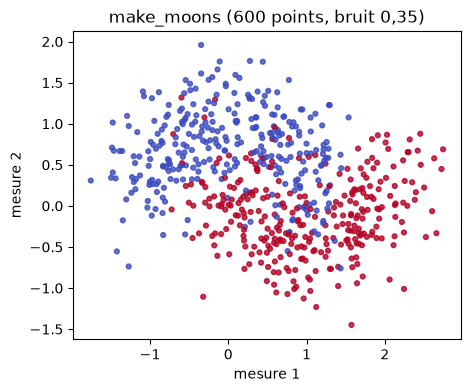

In [2]:
X, y = make_moons(n_samples=600, noise=0.35, random_state=SEED_DATA)

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED_DATA
)

print("Apprentissage :", X_train_full.shape, "| proportions :", np.bincount(y_train_full) / len(y_train_full))
print("Test          :", X_test.shape, "| proportions :", np.bincount(y_test) / len(y_test))

plt.figure(figsize=(5, 4))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=12, alpha=0.8)
plt.title("make_moons (600 points, bruit 0,35)")
plt.xlabel("mesure 1"); plt.ylabel("mesure 2")
plt.show()

## 2. Mise à l'échelle sans fuite

Le `StandardScaler` est ajusté (`fit`) sur l'apprentissage seulement, puis appliqué (`transform`) à l'apprentissage et au test.

In [3]:
scaler = StandardScaler()
X_train_full_s = scaler.fit_transform(X_train_full)   # fit sur l'apprentissage seulement
X_test_s = scaler.transform(X_test)                   # le test est seulement transformé

print("Moyenne apprentissage (≈0) :", X_train_full_s.mean(axis=0).round(3))
print("Écart-type apprentissage (≈1) :", X_train_full_s.std(axis=0).round(3))

Moyenne apprentissage (≈0) : [-0.  0.]
Écart-type apprentissage (≈1) : [1. 1.]


## 3. Référence non neuronale : régression logistique

In [4]:
def mesures(y_vrai, y_pred):
    return {
        "accuracy": accuracy_score(y_vrai, y_pred),
        "f1_macro": f1_score(y_vrai, y_pred, average="macro"),
        "cm": confusion_matrix(y_vrai, y_pred),
    }

logreg = LogisticRegression(random_state=SEED_DATA)
logreg.fit(X_train_full_s, y_train_full)

res_ref = mesures(y_test, logreg.predict(X_test_s))
print(f"Régression logistique | accuracy = {res_ref['accuracy']:.3f} | F1 macro = {res_ref['f1_macro']:.3f}")

Régression logistique | accuracy = 0.833 | F1 macro = 0.833


## 4. Réseau Keras avec arrêt précoce

La validation est tirée de l'apprentissage (20 %, stratifiée). L'arrêt précoce surveille la perte de validation
et restaure les meilleurs poids. Le test n'intervient pas dans l'entraînement.

In [5]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_full_s, y_train_full, test_size=0.2, stratify=y_train_full, random_state=SEED_DATA
)
print("Entraînement :", X_tr.shape, "| Validation :", X_val.shape, "| Test :", X_test_s.shape)


def construire_reseau(hidden, lr, dropout):
    model = keras.Sequential([
        keras.layers.Input(shape=(2,)),
        keras.layers.Dense(hidden, activation="relu"),
        keras.layers.Dropout(dropout),
        keras.layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )
    return model


def entrainer_et_mesurer(hidden, lr, dropout, seed):
    keras.utils.set_random_seed(seed)
    model = construire_reseau(hidden, lr, dropout)
    arret = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=20, restore_best_weights=True
    )
    hist = model.fit(
        X_tr, y_tr,
        validation_data=(X_val, y_val),
        epochs=300, batch_size=32,
        callbacks=[arret], verbose=0,
    )
    y_pred = (model.predict(X_test_s, verbose=0).ravel() > 0.5).astype(int)
    res = mesures(y_test, y_pred)
    res["epochs"] = len(hist.history["loss"])
    return res

Entraînement : (360, 2) | Validation : (90, 2) | Test : (150, 2)


## 5. Deux réglages du réseau, chacun sur trois grains

- **Réglage A** : petite couche cachée (8 neurones), sans dropout, taux d'apprentissage 0,01.
- **Réglage B** : couche cachée plus large (32 neurones), dropout 0,2, taux d'apprentissage 0,01.

In [6]:
REGLAGES = {
    "A (8 neurones, dropout 0)":   dict(hidden=8,  lr=0.01, dropout=0.0),
    "B (32 neurones, dropout 0,2)": dict(hidden=32, lr=0.01, dropout=0.2),
}

resultats = []   # une ligne par (réglage, grain)
for nom, params in REGLAGES.items():
    for seed in SEEDS:
        r = entrainer_et_mesurer(seed=seed, **params)
        r.update({"reglage": nom, "seed": seed})
        resultats.append(r)
        print(f"{nom} | grain {seed} | epochs = {r['epochs']:>3} | "
              f"accuracy = {r['accuracy']:.3f} | F1 macro = {r['f1_macro']:.3f}")

E0000 00:00:1792575509.257668  181044 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.


A (8 neurones, dropout 0) | grain 0 | epochs = 300 | accuracy = 0.893 | F1 macro = 0.893
A (8 neurones, dropout 0) | grain 1 | epochs =  77 | accuracy = 0.887 | F1 macro = 0.887
A (8 neurones, dropout 0) | grain 2 | epochs = 203 | accuracy = 0.880 | F1 macro = 0.880
B (32 neurones, dropout 0,2) | grain 0 | epochs =  94 | accuracy = 0.887 | F1 macro = 0.887
B (32 neurones, dropout 0,2) | grain 1 | epochs = 149 | accuracy = 0.893 | F1 macro = 0.893
B (32 neurones, dropout 0,2) | grain 2 | epochs = 118 | accuracy = 0.893 | F1 macro = 0.893


## 6. Mesures : accuracy, F1 macro, matrice de confusion

In [7]:
df = pd.DataFrame([{k: v for k, v in r.items() if k != "cm"} for r in resultats])

synthese = (
    df.groupby("reglage")[["accuracy", "f1_macro"]]
      .agg(["mean", "std"])
      .round(3)
)
display(synthese)

# Tableau comparatif avec la référence
tableau = pd.DataFrame({
    "accuracy": {"Régression logistique": res_ref["accuracy"],
                 **{nom: df[df.reglage == nom].accuracy.mean() for nom in REGLAGES}},
    "F1 macro": {"Régression logistique": res_ref["f1_macro"],
                 **{nom: df[df.reglage == nom].f1_macro.mean() for nom in REGLAGES}},
}).round(3)
display(tableau)

accuracy        f1_macro       
                                 mean    std     mean    std
reglage                                                     
A (8 neurones, dropout 0)       0.887  0.007    0.887  0.007
B (32 neurones, dropout 0,2)    0.891  0.004    0.891  0.004

,accuracy,F1 macro
Régression logistique,0.833,0.833
"A (8 neurones, dropout 0)",0.887,0.887
"B (32 neurones, dropout 0,2)",0.891,0.891


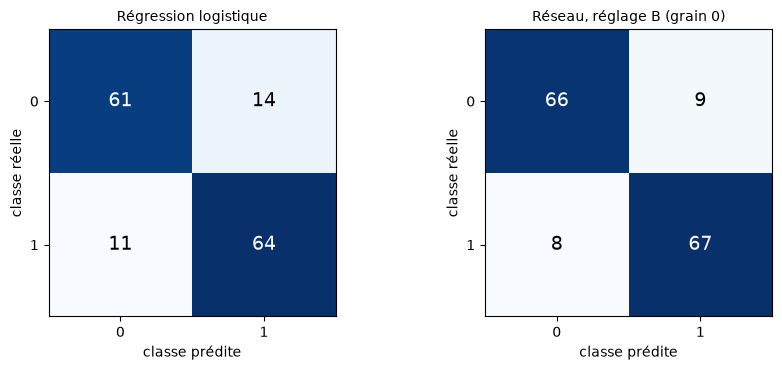

In [8]:
# Meilleur réglage = meilleure accuracy moyenne sur les trois grains
meilleur_nom = df.groupby("reglage").accuracy.mean().idxmax()
res_meilleur = [r for r in resultats if r["reglage"] == meilleur_nom and r["seed"] == SEEDS[0]][0]

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, titre, cm in [
    (axes[0], "Régression logistique", res_ref["cm"]),
    (axes[1], f"Réseau, réglage {meilleur_nom.split(' ')[0]} (grain {SEEDS[0]})", res_meilleur["cm"]),
]:
    ax.imshow(cm, cmap="Blues")
    ax.set_title(titre, fontsize=10)
    ax.set_xlabel("classe prédite"); ax.set_ylabel("classe réelle")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=14)
plt.tight_layout()
plt.show()

## 7. Marge de bruit liée à la taille du test

Formule du TP5 : `1,96 × racine( p(1−p) / n )`, avec `n` la taille du test et `p` l'accuracy mesurée.
On compare l'écart réseau − référence à cette marge.

In [9]:
n_test = len(y_test)

def marge_bruit(p, n):
    return 1.96 * np.sqrt(p * (1 - p) / n)

acc_ref = res_ref["accuracy"]
acc_reseau = df[df.reglage == meilleur_nom].accuracy.mean()

marge_ref = marge_bruit(acc_ref, n_test)
marge_reseau = marge_bruit(acc_reseau, n_test)
ecart = acc_reseau - acc_ref

print(f"Taille du test n = {n_test}")
print(f"Référence : accuracy = {acc_ref:.3f}  ± {marge_ref:.3f}")
print(f"Réseau    : accuracy = {acc_reseau:.3f}  ± {marge_reseau:.3f}  (réglage {meilleur_nom})")
print(f"Écart réseau − référence = {ecart:+.3f}  | marge de bruit = {marge_reseau:.3f}")
print("Écart plus grand que la marge ?", "OUI" if abs(ecart) > marge_reseau else "NON")

Taille du test n = 150
Référence : accuracy = 0.833  ± 0.060
Réseau    : accuracy = 0.891  ± 0.050  (réglage B (32 neurones, dropout 0,2))
Écart réseau − référence = +0.058  | marge de bruit = 0.050
Écart plus grand que la marge ? OUI


## 8. Conclusion

Le texte ci-dessous est construit à partir des chiffres calculés plus haut : il se met à jour si on relance le notebook.

In [10]:
f1_ref = res_ref["f1_macro"]
f1_reseau = df[df.reglage == meilleur_nom].f1_macro.mean()
ecart_f1 = f1_reseau - f1_ref
ecart_pts = ecart * 100

if ecart > marge_reseau:
    verdict = ("**Oui, le réseau est meilleur que la référence, et ce gain dépasse le bruit.** "
               "On peut donc raisonnablement le garantir sur ce test.")
elif ecart > 0:
    verdict = ("**Le réseau est un peu meilleur en apparence, mais ce gain reste plus petit que la marge de bruit.** "
               "On ne peut pas garantir qu'il fait mieux : la différence peut venir du hasard du découpage.")
else:
    verdict = ("**Non, le réseau n'est pas meilleur que la référence.** "
               "La méthode simple fait au moins aussi bien, et elle est plus facile à expliquer.")

texte = f"""
**Réponse au client.** {verdict}

**Les chiffres.** Sur {n_test} points de test, la régression logistique obtient une accuracy de {acc_ref:.3f}
(F1 macro {f1_ref:.3f}). Le meilleur réglage du réseau ({meilleur_nom}) obtient {acc_reseau:.3f} en moyenne sur
{len(SEEDS)} grains (F1 macro {f1_reseau:.3f}). L'écart est de {ecart_pts:+.1f} point(s) d'accuracy
({ecart_f1:+.3f} en F1 macro).

**Le bruit.** Avec seulement {n_test} points de test, la marge de bruit est d'environ ±{marge_reseau:.3f}
(±{marge_reseau*100:.1f} points). L'écart mesuré ({abs(ecart):.3f}) est
{'plus grand' if abs(ecart) > marge_reseau else 'plus petit'} que cette marge.

**Les limites.** Les classes `make_moons` ne se séparent pas par une droite, ce qui laisse de la place au réseau ;
mais avec un bruit de 0,35, les deux classes se chevauchent, et aucun modèle ne peut dépasser un certain plafond.
Les deux réglages ont été testés sur trois grains seulement, et un seul découpage apprentissage/test a été utilisé.
Pour une garantie plus solide, il faudrait un test plus grand ou une validation croisée.
"""
display(Markdown(texte))


**Réponse au client.** **Oui, le réseau est meilleur que la référence, et ce gain dépasse le bruit.** On peut donc raisonnablement le garantir sur ce test.

**Les chiffres.** Sur 150 points de test, la régression logistique obtient une accuracy de 0.833
(F1 macro 0.833). Le meilleur réglage du réseau (B (32 neurones, dropout 0,2)) obtient 0.891 en moyenne sur
3 grains (F1 macro 0.891). L'écart est de +5.8 point(s) d'accuracy
(+0.058 en F1 macro).

**Le bruit.** Avec seulement 150 points de test, la marge de bruit est d'environ ±0.050
(±5.0 points). L'écart mesuré (0.058) est
plus grand que cette marge.

**Les limites.** Les classes `make_moons` ne se séparent pas par une droite, ce qui laisse de la place au réseau ;
mais avec un bruit de 0,35, les deux classes se chevauchent, et aucun modèle ne peut dépasser un certain plafond.
Les deux réglages ont été testés sur trois grains seulement, et un seul découpage apprentissage/test a été utilisé.
Pour une garantie plus solide, il faudrait un test plus grand ou une validation croisée.
